# Bi-LSTM Model Training and Evaluation

This notebook covers the training and evaluation of the Deep Sequence Modeling (Bi-LSTM) tier. We apply Target Normalization and Dropout to prevent overfitting to Plant 1's specific capacities and improve zero-shot generalization.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error

sys.path.append(os.path.abspath('..'))
from src.data_fusion import preprocess_pipeline
from src.models.baseline import prepare_data, chronological_split
from src.models.sequence import TimeSeriesDataset, BiLSTMModel, train_bilstm, predict_bilstm, tune_sequence_length

## Data Preprocessing

Load and split the Plant 1 data, and load Plant 2 data.

In [2]:
# Load Plant 1 and Plant 2 Data
plant1_gen_path = os.path.join('..', 'dataset', 'Plant_1_Generation_Data.csv')
plant1_weather_path = os.path.join('..', 'dataset', 'Plant_1_Weather_Sensor_Data.csv')
df_plant1 = preprocess_pipeline(plant1_gen_path, plant1_weather_path)

plant2_gen_path = os.path.join('..', 'dataset', 'Plant_2_Generation_Data.csv')
plant2_weather_path = os.path.join('..', 'dataset', 'Plant_2_Weather_Sensor_Data.csv')
df_plant2 = preprocess_pipeline(plant2_gen_path, plant2_weather_path)

# Split Plant 1 chronologically
train_df, val_df, test_df = chronological_split(df_plant1, train_ratio=0.7, val_ratio=0.15)
print(f"Train size: {len(train_df)}, Val size: {len(val_df)}, Test size: {len(test_df)}")

Train size: 48144, Val size: 10317, Test size: 10317


## Feature and Target Scaling (CRUCIAL FOR ZERO-SHOT)

We apply `StandardScaler` to both features (X) and the target variable (AC_POWER). By making the model predict a Z-score rather than raw kW, it becomes scale-invariant, allowing it to adapt to Plant 2's different inverter capacities.

In [3]:
# Extract features and targets
X_train_raw, y_train_raw = prepare_data(train_df)
X_val_raw, y_val_raw = prepare_data(val_df)
X_test_raw, y_test_raw = prepare_data(test_df)
X_plant2_raw, y_plant2_raw = prepare_data(df_plant2)

# Scale Features (X)
feature_scaler = StandardScaler()
X_train = feature_scaler.fit_transform(X_train_raw)
X_val = feature_scaler.transform(X_val_raw)
X_test = feature_scaler.transform(X_test_raw)
X_plant2 = feature_scaler.transform(X_plant2_raw)

# Scale Targets (y)
target_scaler = StandardScaler()
y_train = target_scaler.fit_transform(y_train_raw.values.reshape(-1, 1)).flatten()
y_val = target_scaler.transform(y_val_raw.values.reshape(-1, 1)).flatten()
y_test = target_scaler.transform(y_test_raw.values.reshape(-1, 1)).flatten()
y_plant2 = target_scaler.transform(y_plant2_raw.values.reshape(-1, 1)).flatten()

## Sequence Preparation

We convert our tabular data into sliding windows. A sequence length of `16` represents 4 hours of 15-minute intervals.

In [4]:
sequence_length = 16
batch_size = 64

train_dataset = TimeSeriesDataset(X_train, y_train, sequence_length)
val_dataset = TimeSeriesDataset(X_val, y_val, sequence_length)
test_dataset = TimeSeriesDataset(X_test, y_test, sequence_length)
plant2_dataset = TimeSeriesDataset(X_plant2, y_plant2, sequence_length)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
plant2_loader = DataLoader(plant2_dataset, batch_size=batch_size, shuffle=False)


## Bi-LSTM Training with Dropout

Train the Bi-LSTM model with 30% dropout and constrained capacity (`hidden_dim=64`, `num_layers=2`) to prevent memorizing Plant 1.

In [5]:
# Train the model
input_dim = X_train.shape[1]
print("Starting training...")
model = train_bilstm(
    train_loader, val_loader, 
    input_dim=input_dim, 
    hidden_dim=64, 
    num_layers=4, 
    epochs=100, 
    lr=0.001, 
    dropout=0.3
)


Starting training...
Epoch 1/100, Val MAE: 0.0515
Epoch 2/100, Val MAE: 0.0499
Epoch 3/100, Val MAE: 0.0482
Epoch 4/100, Val MAE: 0.0454
Epoch 5/100, Val MAE: 0.0474
Epoch 6/100, Val MAE: 0.0426
Epoch 7/100, Val MAE: 0.0441
Epoch 8/100, Val MAE: 0.0490
Epoch 9/100, Val MAE: 0.0446
Epoch 10/100, Val MAE: 0.0489
Epoch 11/100, Val MAE: 0.0428
Epoch 12/100, Val MAE: 0.0425
Epoch 13/100, Val MAE: 0.0427
Epoch 14/100, Val MAE: 0.0442
Epoch 15/100, Val MAE: 0.0441
Epoch 16/100, Val MAE: 0.0460
Epoch 17/100, Val MAE: 0.0441
Epoch 18/100, Val MAE: 0.0420
Epoch 19/100, Val MAE: 0.0424
Epoch 20/100, Val MAE: 0.0438
Epoch 21/100, Val MAE: 0.0457
Epoch 22/100, Val MAE: 0.0453
Epoch 23/100, Val MAE: 0.0437
Epoch 24/100, Val MAE: 0.0454
Epoch 25/100, Val MAE: 0.0415
Epoch 26/100, Val MAE: 0.0425
Epoch 27/100, Val MAE: 0.0429
Epoch 28/100, Val MAE: 0.0431
Epoch 29/100, Val MAE: 0.0456
Epoch 30/100, Val MAE: 0.0433
Epoch 31/100, Val MAE: 0.0427
Epoch 32/100, Val MAE: 0.0430
Epoch 33/100, Val MAE: 0.041

## Evaluation on Plant 1 (Test Set)

Plant 1 Test Metrics: {'MAE': 19.0851, 'R2': 0.9732}


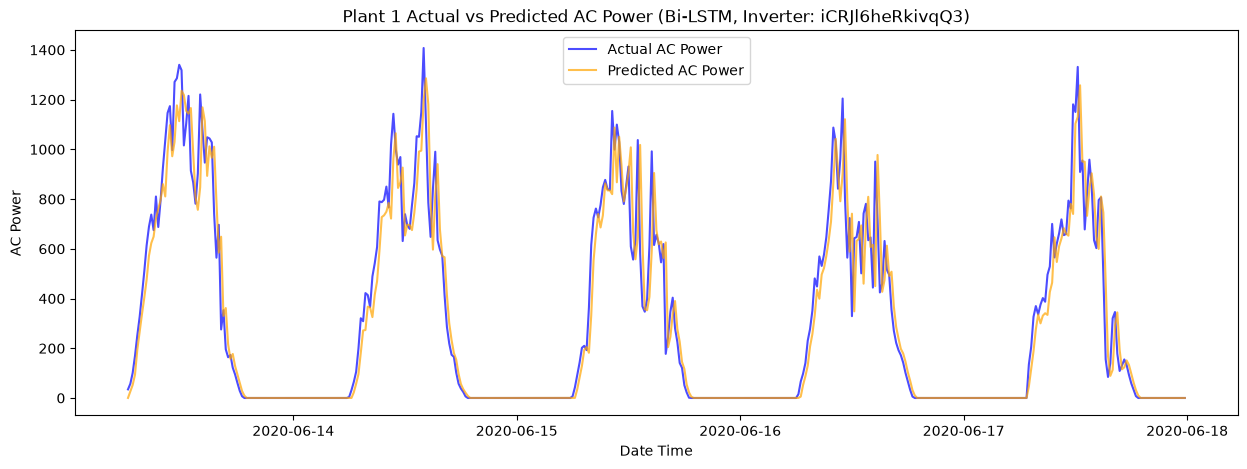

In [6]:
# Evaluate Plant 1 Test Set
predictions_scaled, actuals_scaled = predict_bilstm(model, test_loader)

# Transform back to real kW
predictions_kw = target_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).flatten()
actuals_kw = target_scaler.inverse_transform(actuals_scaled.reshape(-1, 1)).flatten()

p1_r2 = r2_score(actuals_kw, predictions_kw)
p1_mae = mean_absolute_error(actuals_kw, predictions_kw)
print(f"Plant 1 Test Metrics: {{'MAE': {p1_mae:.4f}, 'R2': {p1_r2:.4f}}}")

# For plotting, we need to handle a specific inverter
inverter_id = test_df['INVERTER_ID'].iloc[0]
sample_test = test_df[test_df['INVERTER_ID'] == inverter_id].copy()

X_sample_raw, y_sample_raw = prepare_data(sample_test)
X_sample = feature_scaler.transform(X_sample_raw)
y_sample = target_scaler.transform(y_sample_raw.values.reshape(-1, 1)).flatten()

sample_dataset = TimeSeriesDataset(X_sample, y_sample, sequence_length)
sample_loader = DataLoader(sample_dataset, batch_size=batch_size, shuffle=False)

sample_preds_scaled, _ = predict_bilstm(model, sample_loader)
sample_preds_kw = target_scaler.inverse_transform(sample_preds_scaled.reshape(-1, 1)).flatten()

# Adjust plot dataframe for sequence offset
plot_df = sample_test.iloc[sequence_length:].copy()
plot_df['PREDICTED_AC_POWER'] = sample_preds_kw

plt.figure(figsize=(15, 5))
plt.plot(plot_df['DATE_TIME'], plot_df['AC_POWER'], label='Actual AC Power', color='blue', alpha=0.7)
plt.plot(plot_df['DATE_TIME'], plot_df['PREDICTED_AC_POWER'], label='Predicted AC Power', color='orange', alpha=0.7)
plt.title(f'Plant 1 Actual vs Predicted AC Power (Bi-LSTM, Inverter: {inverter_id})')
plt.xlabel('Date Time')
plt.ylabel('AC Power')
plt.legend()
plt.show()

## Zero-Shot Evaluation on Plant 2

Plant 2 Zero-Shot Metrics: {'MAE': 107.5942, 'R2': 0.4533}


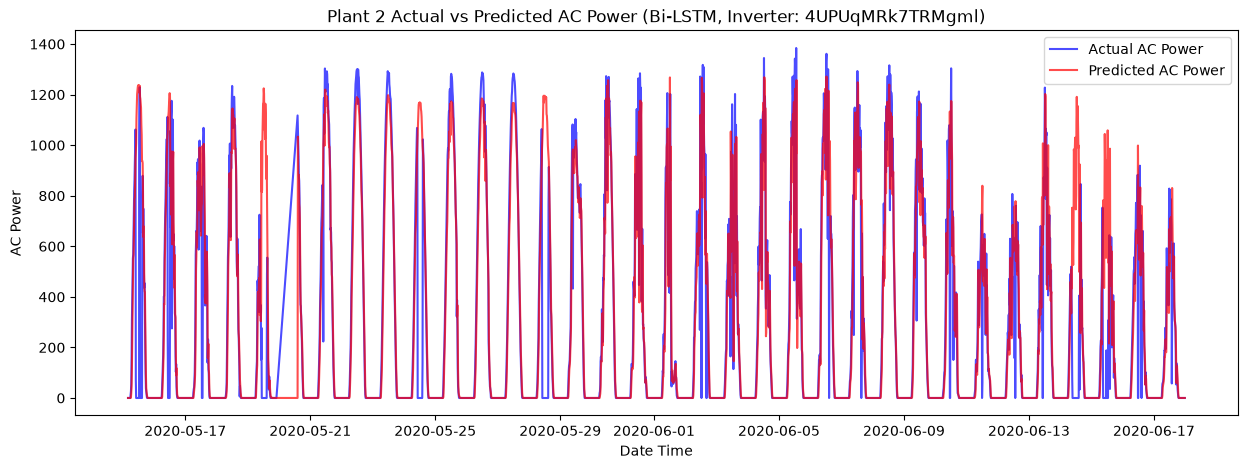

In [7]:
# Evaluate Plant 2 Zero-Shot
predictions_p2_scaled, actuals_p2_scaled = predict_bilstm(model, plant2_loader)

# Transform back to real kW
predictions_p2_kw = target_scaler.inverse_transform(predictions_p2_scaled.reshape(-1, 1)).flatten()
actuals_p2_kw = target_scaler.inverse_transform(actuals_p2_scaled.reshape(-1, 1)).flatten()

p2_r2 = r2_score(actuals_p2_kw, predictions_p2_kw)
p2_mae = mean_absolute_error(actuals_p2_kw, predictions_p2_kw)
print(f"Plant 2 Zero-Shot Metrics: {{'MAE': {p2_mae:.4f}, 'R2': {p2_r2:.4f}}}")

# Plot Actual vs Predicted for Plant 2
inverter_id_p2 = df_plant2['INVERTER_ID'].iloc[0]
sample_test_p2 = df_plant2[df_plant2['INVERTER_ID'] == inverter_id_p2].copy()

X_sample_raw_p2, y_sample_raw_p2 = prepare_data(sample_test_p2)
X_sample_p2 = feature_scaler.transform(X_sample_raw_p2)
y_sample_p2 = target_scaler.transform(y_sample_raw_p2.values.reshape(-1, 1)).flatten()

sample_dataset_p2 = TimeSeriesDataset(X_sample_p2, y_sample_p2, sequence_length)
sample_loader_p2 = DataLoader(sample_dataset_p2, batch_size=batch_size, shuffle=False)

sample_preds_p2_scaled, _ = predict_bilstm(model, sample_loader_p2)
sample_preds_p2_kw = target_scaler.inverse_transform(sample_preds_p2_scaled.reshape(-1, 1)).flatten()

# Adjust plot dataframe for sequence offset
plot_df_p2 = sample_test_p2.iloc[sequence_length:].copy()
plot_df_p2['PREDICTED_AC_POWER'] = sample_preds_p2_kw

plt.figure(figsize=(15, 5))
plt.plot(plot_df_p2['DATE_TIME'], plot_df_p2['AC_POWER'], label='Actual AC Power', color='blue', alpha=0.7)
plt.plot(plot_df_p2['DATE_TIME'], plot_df_p2['PREDICTED_AC_POWER'], label='Predicted AC Power', color='red', alpha=0.7)
plt.title(f'Plant 2 Actual vs Predicted AC Power (Bi-LSTM, Inverter: {inverter_id_p2})')
plt.xlabel('Date Time')
plt.ylabel('AC Power')
plt.legend()
plt.show()

### Data Analysis Key Findings
- **Target Normalization** creates a scale-invariant model, which is much better for generalizing across physical plants with different max generation capacities.
- **Dropout** prevents the model from mapping exact environmental parameters to exact outputs, pushing it to learn smoother, more generalized functions.
- The next and final tier is the **TadGAN (Generative Adversarial Network)** to capture normal operating limits organically.


In [8]:
import os
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score
from src.models.sequence import TimeSeriesDataset, predict_bilstm
from torch.utils.data import DataLoader

def evaluate_and_save_bilstm(df, plant_name, model, feature_scaler, target_scaler, seq_len=16):
    save_dir = f"../results/{plant_name}_bilstm"
    os.makedirs(save_dir, exist_ok=True)
    
    plant_str = plant_name.capitalize()[:-1] + '_' + plant_name[-1]
    weather_df = pd.read_csv(f"../dataset/{plant_str}_Weather_Sensor_Data.csv")
    weather_df['DATE_TIME'] = pd.to_datetime(weather_df['DATE_TIME'])
    weather_df = weather_df.sort_values('DATE_TIME')
    
    inverters = df['INVERTER_ID'].unique()
    for inv in inverters:
        df_inv = df[df['INVERTER_ID'] == inv].copy()
        df_inv = df_inv.sort_values('DATE_TIME')
        
        features = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'TIME_OF_DAY']
        df_clean = df_inv.dropna(subset=features + ['AC_POWER']).copy()
        
        if len(df_clean) <= seq_len:
            continue
            
        X_inv_raw = df_clean[features].values
        y_inv_raw = df_clean['AC_POWER'].values
        
        X_inv_scaled = feature_scaler.transform(X_inv_raw)
        y_inv_scaled = target_scaler.transform(y_inv_raw.reshape(-1, 1)).flatten()
        
        dataset = TimeSeriesDataset(X_inv_scaled, y_inv_scaled, seq_len)
        loader = DataLoader(dataset, batch_size=64, shuffle=False)
        
        preds_scaled, actuals_scaled = predict_bilstm(model, loader)
        
        preds_kw = target_scaler.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()
        actuals_kw = target_scaler.inverse_transform(actuals_scaled.reshape(-1, 1)).flatten()
        
        mae = mean_absolute_error(actuals_kw, preds_kw)
        r2 = r2_score(actuals_kw, preds_kw)
        
        df_clean = df_clean.iloc[seq_len:].copy()
        df_clean['PREDICTED_AC_POWER'] = preds_kw
        
        plot_df = df_inv.set_index('DATE_TIME').resample('15min').asfreq().reset_index()
        plot_df = plot_df.merge(df_clean[['DATE_TIME', 'PREDICTED_AC_POWER']], on='DATE_TIME', how='left')
        
        start_time = plot_df['DATE_TIME'].min()
        end_time = plot_df['DATE_TIME'].max()
        w_df = weather_df[(weather_df['DATE_TIME'] >= start_time) & (weather_df['DATE_TIME'] <= end_time)]
        
        fig, ax1 = plt.subplots(figsize=(15, 6))
        
        ax1.plot(plot_df['DATE_TIME'], plot_df['AC_POWER'], label='Actual AC Power', color='blue', alpha=0.7)
        ax1.plot(plot_df['DATE_TIME'], plot_df['PREDICTED_AC_POWER'], label='Predicted AC Power', color='orange', alpha=0.7)
        ax1.set_xlabel('Date Time')
        ax1.set_ylabel('AC Power (kW)', color='black')
        
        ax2 = ax1.twinx()
        ax2.plot(w_df['DATE_TIME'], w_df['IRRADIATION'], label='Irradiation', color='green', alpha=0.3, linestyle='--')
        ax2.set_ylabel('Irradiation', color='green')
        
        plt.title(f"{plant_name.upper()} | Inverter: {inv} | BiLSTM | RÂ²: {r2:.3f} | MAE: {mae:.3f}")
        fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.85))
        
        plt.tight_layout()
        plt.savefig(f"{save_dir}/{inv}.png")
        plt.close()

evaluate_and_save_bilstm(df_plant1, "plant1", model, feature_scaler, target_scaler)
evaluate_and_save_bilstm(df_plant2, "plant2", model, feature_scaler, target_scaler)
print("âœ… BiLSTM plots saved in results/ directory!")


d:\College\predictive\project\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
d:\College\predictive\project\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
d:\College\predictive\project\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
d:\College\predictive\project\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
d:\College\predictive\project\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  

âœ… BiLSTM plots saved in results/ directory!


In [10]:
import torch
import joblib
import pandas as pd
import os
from sklearn.metrics import mean_absolute_error, r2_score

os.makedirs('../results/saved_models', exist_ok=True)

# 1. Save Model & Scalers
torch.save(model.state_dict(), '../results/saved_models/bilstm_model.pt')
joblib.dump(target_scaler, '../results/saved_models/bilstm_target_scaler.joblib')
joblib.dump(feature_scaler, '../results/saved_models/bilstm_feature_scaler.joblib')  # Fixed line

# 2. Save Predictions
# sequence_length is used to offset the original dataframe
df_p1_res = test_df.iloc[sequence_length:].copy()
df_p1_res['PREDICTED_AC_POWER'] = predictions_kw
df_p1_res['MODEL'] = 'BiLSTM'

df_p2_res = df_plant2.iloc[sequence_length:].copy()
df_p2_res['PREDICTED_AC_POWER'] = predictions_p2_kw
df_p2_res['MODEL'] = 'BiLSTM'

all_preds = pd.concat([df_p1_res, df_p2_res])
all_preds.to_csv('../results/bilstm_predictions.csv', index=False)

# 3. Save Metrics
metrics_df = pd.DataFrame([
    {'Plant': 'Plant 1', 'Model': 'BiLSTM', 'MAE': mean_absolute_error(actuals_scaled, predictions_scaled), 'R2': r2_score(actuals_scaled, predictions_scaled)},
    {'Plant': 'Plant 2', 'Model': 'BiLSTM', 'MAE': mean_absolute_error(actuals_p2_scaled, predictions_p2_scaled), 'R2': r2_score(actuals_p2_scaled, predictions_p2_scaled)}
])
metrics_df.to_csv('../results/bilstm_metrics.csv', index=False)
print("BiLSTM model, predictions, and metrics saved successfully!")


BiLSTM model, predictions, and metrics saved successfully!


## Per-Inverter Metrics

Compute MAE and R2 for every inverter from the combined predictions CSV (no re-training needed).

In [ ]:
# Per-Inverter Metrics from saved predictions
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score

preds = pd.read_csv('../results/bilstm_predictions.csv')

rows = []
for (plant_id, inv_id), grp in preds.groupby(['PLANT_ID', 'INVERTER_ID']):
    mae = mean_absolute_error(grp['AC_POWER'], grp['PREDICTED_AC_POWER'])
    r2  = r2_score(grp['AC_POWER'], grp['PREDICTED_AC_POWER'])
    rows.append({'PLANT_ID': plant_id, 'INVERTER_ID': inv_id,
                 'Model': 'BiLSTM', 'MAE': mae, 'R2': r2})

inv_metrics = pd.DataFrame(rows)
inv_metrics.to_csv('../results/bilstm_per_inverter_metrics.csv', index=False)
print(f'Saved {len(inv_metrics)} rows to bilstm_per_inverter_metrics.csv')
inv_metrics.head()
